<a href="https://colab.research.google.com/github/esranuraltinay/Kalp-Yetmezligi-Olum-Riski-Tahmini/blob/main/02_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelleme ve Değerlendirme**

Bu notebook'ta kalp yetmezliği hastalarının başlangıçtaki klinik ve laboratuvar verilerini kullanarak takip süresi içerisinde ölüm olayının gerçekleşip gerçekleşmediğini tahmin eden makine öğrenmesi modelleri geliştirilecektir.

##İzlenecek Adımlar

1. Verinin modellemeye hazırlanması

2. Ön işleme kararlarının uygulanması

3. Eğitim ve doğrulama stratejisinin oluşturulması

4. Logistic Regression, Random Forest ve XGBoost modellerinin geliştirilmesi

5. Modellerin performanslarının karşılaştırılması

6. ROC, Precision-Recall ve kalibrasyon eğrilerinin incelenmesi

##Yöntemsel Kararlar

Hedef değişken: DEATH_EVENT

- Kullanılacak öznitelik sayısı: 11

- time değişkeni başlangıç tahmininde bilinmediği için model dışında tutulacaktır.

- Model değerlendirmesindeNested Cross-Validation kullanılacaktır.

- Rastgele işlemlerde tekrarlanabilirlikiçin SEED = 42 kullanılacaktır


## **Kütüphanelerin Yüklenmesi**

In [26]:
# Veri işleme
import numpy as np
import pandas as pd

# Görselleştirme
import matplotlib.pyplot as plt
import seaborn as sns

# Veri ön işleme
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model
from sklearn.linear_model import LogisticRegression

# Model değerlendirme
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# Rastgelelik ve tekrarlanabilirlik
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Kütüphaneler başarıyla yüklendi.")
print("SEED:", SEED)

Kütüphaneler başarıyla yüklendi.
SEED: 42


## **Verinin Yüklenmesi**

In [27]:
# UCI veri setinin yüklenmesi
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv"

df = pd.read_csv(url)

# Veri setinin boyutunu kontrol etme
print("Veri setinin boyutu:", df.shape)

# İlk 5 kaydı görüntüleme
df.head()

Veri setinin boyutu: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## **Hedef Değişken ve Özniteliklerin Ayrılması**

Modelin tahmin edeceği hedef değişken DEATH_EVENT olarak belirlenmiştir.

Veri setindeki time değişkeni hastanın takip süresini göstermektedir. Çalışmanın amacı başlangıçtaki klinik verilerle tahmin yapmak olduğundan tahmin anında bilinmeyen bu değişken ana modelden çıkarılmıştır.

Böylece modelde 11 öznitelik ve 1 hedef değişken kullanılacaktır.

In [28]:
# Hedef değişkeni belirleme
y = df["DEATH_EVENT"]

# Tahmin sırasında kullanılacak öznitelikleri belirleme
# DEATH_EVENT hedef değişkeni, time ise takip süresi olduğu için çıkarılır.
X = df.drop(columns=["DEATH_EVENT", "time"])

# Veri boyutlarını kontrol etme
print("Öznitelik matrisi boyutu:", X.shape)
print("Hedef değişken boyutu:", y.shape)

print("\nKullanılacak öznitelikler:")
print(X.columns.tolist())

print("\nHedef değişken dağılımı:")
print(y.value_counts())

Öznitelik matrisi boyutu: (299, 11)
Hedef değişken boyutu: (299,)

Kullanılacak öznitelikler:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']

Hedef değişken dağılımı:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


## **Veri Kontrolü**

Modelleme öncesinde özniteliklerde eksik değer, yinelenen kayıt ve veri tipi sorunları kontrol edilmektedir.

Bu kontroller, modelin hatalı veya tutarsız verilerle eğitilmesini önlemek amacıyla yapılmaktadır.

In [29]:
# Eksik değer kontrolü
print("Eksik değer sayıları:")
print(X.isnull().sum())

# Toplam eksik değer sayısı
print("\nToplam eksik değer:", X.isnull().sum().sum())

# Yinelenen satır kontrolü
print("Yinelenen öznitelik satırı sayısı:", X.duplicated().sum())

# Veri tipleri
print("\nVeri tipleri:")
print(X.dtypes)

# Sayısal değişkenlerin özet istatistikleri
print("\nÖzet istatistikler:")
display(X.describe().T)

Eksik değer sayıları:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
dtype: int64

Toplam eksik değer: 0
Yinelenen öznitelik satırı sayısı: 0

Veri tipleri:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
dtype: object

Özet istatistikler:


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


## **Aykırı Değerlerin İncelenmesi**

Sürekli sayısal değişkenlerde aykırı değerleri incelemek amacıyla kutu grafikleri (boxplot) ve IQR (Interquartile Range) yöntemi kullanılmaktadır.

İstatistiksel olarak aykırı görünen değerler doğrudan silinmeyecektir. Bu değerlerin klinik açıdan mümkün olup olmadığı değerlendirilecek,ölçüm hatası olduğuna dair kanıt bulunmadıkça veri korunacaktır.

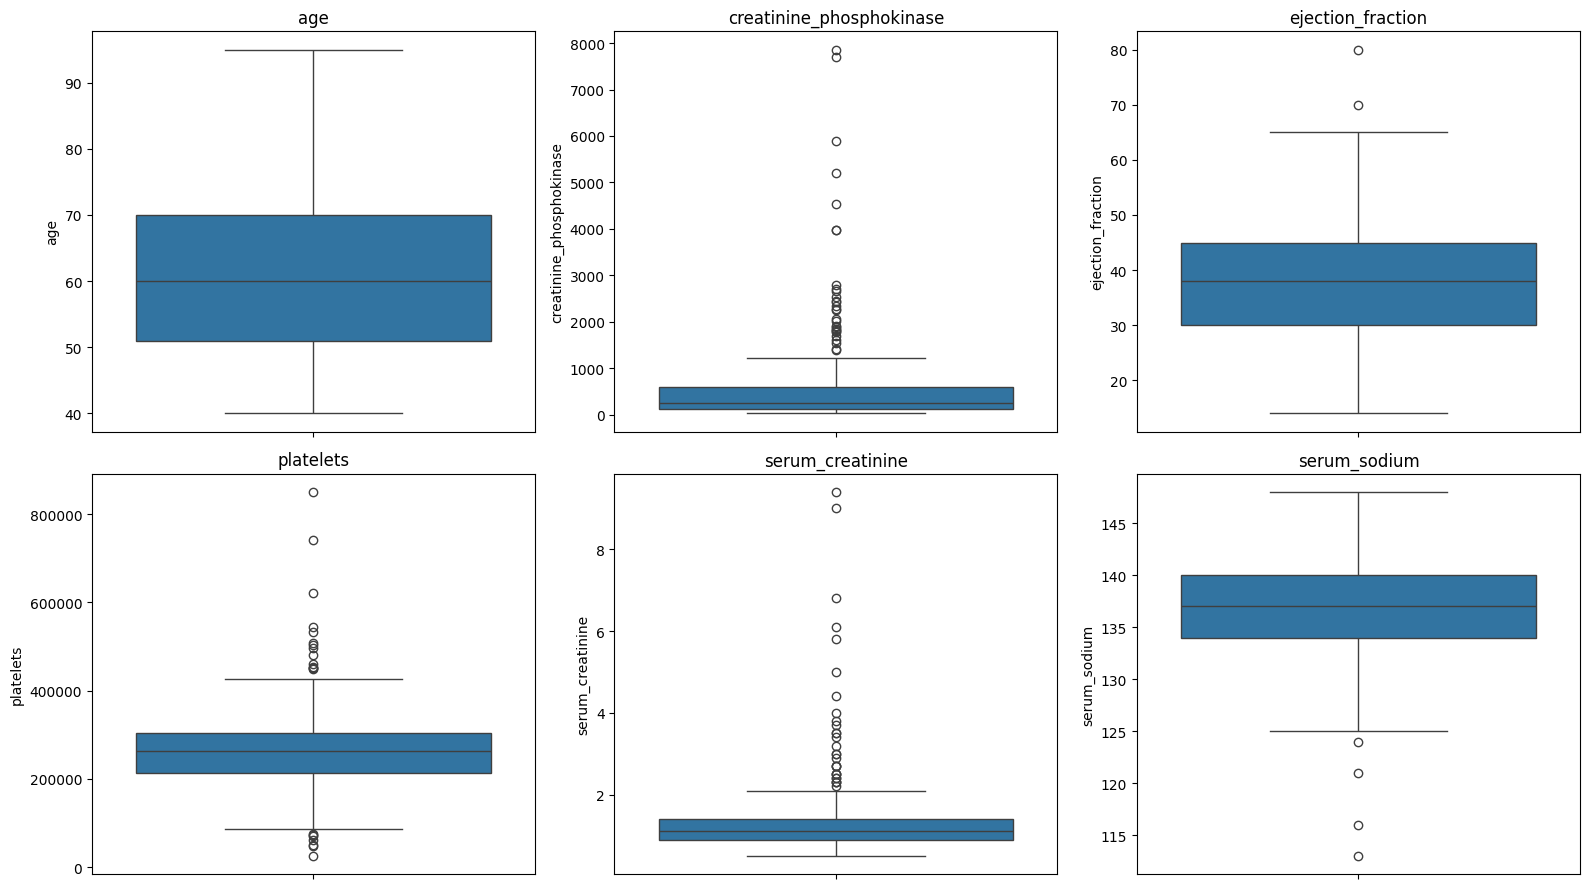

In [30]:
# Sürekli sayısal değişkenleri belirleme
continuous_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

# Boxplot grafikleri
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for column, ax in zip(continuous_columns, axes.flatten()):
    sns.boxplot(y=X[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

## **IQR Yöntemiyle Aykırı Değerlerin Belirlenmesi**

Grafiklerin sayısal olarak incelenmesi.

In [31]:
# IQR yöntemiyle aykırı değer sınırlarını hesaplama

outlier_results = []

for column in continuous_columns:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ][column]

    outlier_results.append({
        "Degisken": column,
        "Alt_Sinir": lower_bound,
        "Ust_Sinir": upper_bound,
        "Aykiri_Deger_Sayisi": len(outliers),
        "Aykiri_Degerler": outliers.tolist()
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Degisken,Alt_Sinir,Ust_Sinir,Aykiri_Deger_Sayisi,Aykiri_Degerler
0,age,22.50,98.50,0,[]
1,creatinine_phosphokinase,-581.75,1280.25,29,"[7861, 2656, 1380, 3964, 7702, 5882, 5209, 187..."
2,ejection_fraction,7.50,67.50,2,"[80, 70]"
3,platelets,76000.00,440000.00,21,"[454000.0, 47000.0, 451000.0, 461000.0, 497000..."
4,serum_creatinine,0.15,2.15,29,"[2.7, 9.4, 4.0, 5.8, 3.0, 3.5, 2.3, 3.0, 4.4, ..."
5,serum_sodium,125.00,149.00,4,"[116, 121, 124, 113]"


**Aykırı Değer Analizi Sonucu**
Değişkenler Boxplot ve IQR yöntemiyle incelenmiştir.  Bazı değişkenlerde istatistiksel olarak aykırı değerler tespit edilmiştir. Bu değerler klinik olarak mümkğn olabileceğinden herhangi bir silme veya kırpma işlemi uygulanmamıştır. Böylece potansiyel klinik bilgilerin korunması amaçlanmıştır.

## **Değişkenlerin Türlerine Göre Ayrılması**

Modelleme öncesinde öznitelikler sürekli sayısal ve ikili değişkenler olarak gruplandırılmıştır.

Sürekli değişkenler farklı ölçü birimlerine ve değerlere sahip oldukları için Logistic Regression modelinde StandardScaler ile ölçeklenecektir.

İkili değişkenler ise 0 ve 1 biçiminde kodlanmış olduğundan mevcut halleriyle korunacaktır.

In [32]:
# Sürekli sayısal değişkenler
continuous_columns = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

# İkili değişkenler
binary_columns = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

# Değişken sayılarını kontrol etme
print("Sürekli değişken sayısı:", len(continuous_columns))
print("İkili değişken sayısı:", len(binary_columns))

print("\nSürekli değişkenler:")
print(continuous_columns)

print("\nİkili değişkenler:")
print(binary_columns)

# Bütün özniteliklerin gruplandırıldığını kontrol etme
all_columns = continuous_columns + binary_columns

print("\nToplam gruplandırılan değişken sayısı:", len(all_columns))
print("Eksik gruplandırma:", set(X.columns) - set(all_columns))
print("Fazladan değişken:", set(all_columns) - set(X.columns))

Sürekli değişken sayısı: 6
İkili değişken sayısı: 5

Sürekli değişkenler:
['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium']

İkili değişkenler:
['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

Toplam gruplandırılan değişken sayısı: 11
Eksik gruplandırma: set()
Fazladan değişken: set()


### **Ölçekleme ve Kategorik Değişkenlere İlişkin Kararlar**

- Sürekli değişkenlerde StandardScaler kullanılacaktır.
- İkili değişkenlerin mevcut 0/1 kodlaması korunacaktır.
- Logistic Regression ölçeklemeye duyarlı olduğu için sürekli değişkenler ölçeklenecektir.
- Ölçekleme işlemi yalnızca eğitim verisi üzerinden öğrenilecektir.
- Veri sızıntısını önlemek amacıyla ön işleme adımları Pipeline içerisinde uygulanacaktır.

Random Forest ve XGBoost gibi ağaç tabanlı modellerde ölçekleme zorunlu olmadığından bu modeller için ayrıca değerlendirme yapılacaktır.

Henüz StandardScaler'ı çalıştırmıyoruz. Çünkü bütün veri setine ölçekleme uygulamak veri sızıntısına neden olabilir. Bunu birazdan çapraz doğrulama yapısının içine yerleştireceğiz.

## **Ön İşleme Pipeline'ının Oluşturulması**

Sürekli değişkenlere StandardScaler uygulanırken, 0/1 biçiminde kodlanmış ikili değişkenler mevcut halleriyle korunacaktır.

Bu işlemler ColumnTransformer kullanılarak tanımlanacaktır. Ön işleme adımları Logistic Regression modeliyle Pipeline içerisinde birleştirilecektir.

Böylece çapraz doğrulama sırasında ölçekleyici yalnızca ilgili eğitim verisinden öğrenerek veri sızıntısı riski azaltılacaktır.

In [33]:
# Sütun bazlı ön işleme için
from sklearn.compose import ColumnTransformer

# Sürekli değişkenlere StandardScaler,
# ikili değişkenlere ise herhangi bir dönüşüm uygulamama
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), continuous_columns),
        ("binary", "passthrough", binary_columns)
    ]
)

# Ön işleme ve Logistic Regression modelini birleştirme
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=SEED
        ))
    ]
)

print("Ön işleme ve model Pipeline yapısı oluşturuldu.")
print(logistic_pipeline)

Ön işleme ve model Pipeline yapısı oluşturuldu.
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['age',
                                                   'creatinine_phosphokinase',
                                                   'ejection_fraction',
                                                   'platelets',
                                                   'serum_creatinine',
                                                   'serum_sodium']),
                                                 ('binary', 'passthrough',
                                                  ['anaemia', 'diabetes',
                                                   'high_blood_pressure', 'sex',
                                                   'smoking'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])


## **Doğrulama Tasarımının Oluşturulması**

Model performansını güvenilir biçimde değerlendirmek ve hiperparametre seçiminin değerlendirme sonuçlarına etkisini azaltmak amacıyla Nested Cross-Validation kullanılacaktır.

- Dış döngüde 5 katlı StratifiedKFold kullanılacaktır.
- İç döngüde 3 katlı StratifiedKFold kullanılacaktır.
- Stratified yaklaşımıyla her kattaki ölüm ve sağkalım sınıflarının oranlarının korunması amaçlanmaktadır.
- Tekrarlanabilirlik için random_state=42 kullanılacaktır.

Veri setindeki her satır bir hastayı temsil ettiğinden bölme birimi hasta kaydıdır.

In [34]:
# Dış çapraz doğrulama: 5 kat
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# İç çapraz doğrulama: 3 kat
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

print("Dış döngü kat sayısı:", outer_cv.get_n_splits())
print("İç döngü kat sayısı:", inner_cv.get_n_splits())
print("Tohum değeri:", SEED)

Dış döngü kat sayısı: 5
İç döngü kat sayısı: 3
Tohum değeri: 42


## **Katmanlı Bölmenin Kontrol Edilmesi**
Sınıf oranları katlarda nasıl dağıldı?

In [35]:
# Dış döngüdeki sınıf dağılımlarını inceleme

for fold, (train_index, test_index) in enumerate(
    outer_cv.split(X, y), start=1
):
    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    print(f"\n--- {fold}. Kat ---")

    print("Eğitim hasta sayısı:", len(train_index))
    print("Değerlendirme hasta sayısı:", len(test_index))

    print(
        "Eğitim pozitif sınıf oranı:",
        round(y_train.mean() * 100, 2), "%"
    )

    print(
        "Değerlendirme pozitif sınıf oranı:",
        round(y_test.mean() * 100, 2), "%"
    )


--- 1. Kat ---
Eğitim hasta sayısı: 239
Değerlendirme hasta sayısı: 60
Eğitim pozitif sınıf oranı: 31.8 %
Değerlendirme pozitif sınıf oranı: 33.33 %

--- 2. Kat ---
Eğitim hasta sayısı: 239
Değerlendirme hasta sayısı: 60
Eğitim pozitif sınıf oranı: 32.22 %
Değerlendirme pozitif sınıf oranı: 31.67 %

--- 3. Kat ---
Eğitim hasta sayısı: 239
Değerlendirme hasta sayısı: 60
Eğitim pozitif sınıf oranı: 32.22 %
Değerlendirme pozitif sınıf oranı: 31.67 %

--- 4. Kat ---
Eğitim hasta sayısı: 239
Değerlendirme hasta sayısı: 60
Eğitim pozitif sınıf oranı: 32.22 %
Değerlendirme pozitif sınıf oranı: 31.67 %

--- 5. Kat ---
Eğitim hasta sayısı: 240
Değerlendirme hasta sayısı: 59
Eğitim pozitif sınıf oranı: 32.08 %
Değerlendirme pozitif sınıf oranı: 32.2 %


## **Logistic Regression Modelinin Hiperparametre Optimizasyonu**

İlk temel model olarak Logistic Regression kullanılacaktır.

Modelin düzenlileştirme parametresi olan C için farklı değerler denenerek en uygun hiperparametre seçilecektir.

Hiperparametre seçimi Nested Cross-Validation yapısının iç döngüsünde gerçekleştirilecektir. Seçim ölçütü olarak ROC-AUC kullanılacaktır.

In [36]:
# Logistic Regression için denenecek C değerleri
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# İç çapraz doğrulamada hiperparametre araması
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=inner_cv,
    n_jobs=-1,
    refit=True
)

print("Hiperparametre araması hazır.")
print("Denenecek C değerleri:", param_grid["model__C"])

Hiperparametre araması hazır.
Denenecek C değerleri: [0.01, 0.1, 1, 10, 100]


## **Nested Cross-Validation ile Model Değerlendirmesi**

Logistic Regression modeli 5 katlı dış ve 3 katlı iç çapraz doğrulama kullanılarak değerlendirilecektir.

İç döngüde seçilen hiperparametre ile model dış eğitim verisinde yeniden eğitilecek ve dış değerlendirme verisinde tahmin gerçekleştirecektir.

Performans AUROC, AUPRC ve Brier skoru üzerinden incelenecektir. Eğitim ve değerlendirme sonuçları ayrı ayrı raporlanacaktır.

In [37]:
# Her dış katın sonuçlarını saklamak için liste
fold_results = []

# Her hastanın dış döngü tahminlerini saklamak için
oof_predictions = np.zeros(len(X))

# Nested Cross-Validation
for fold, (train_index, test_index) in enumerate(
    outer_cv.split(X, y), start=1
):

    print(f"\n========== {fold}. DIŞ KAT ==========")

    # Eğitim ve değerlendirme verilerini ayırma
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # İç döngüde hiperparametre araması
    grid_search.fit(X_train, y_train)

    # En iyi modeli alma
    best_model = grid_search.best_estimator_

    # Eğitim ve değerlendirme olasılık tahminleri
    train_prob = best_model.predict_proba(X_train)[:, 1]
    test_prob = best_model.predict_proba(X_test)[:, 1]

    # Dış değerlendirme kümesinin tahminlerini saklama
    oof_predictions[test_index] = test_prob

    # Eğitim performansı
    train_auc = roc_auc_score(y_train, train_prob)
    train_ap = average_precision_score(y_train, train_prob)
    train_brier = brier_score_loss(y_train, train_prob)

    # Dış değerlendirme performansı
    test_auc = roc_auc_score(y_test, test_prob)
    test_ap = average_precision_score(y_test, test_prob)
    test_brier = brier_score_loss(y_test, test_prob)

    # Sonuçları kaydetme
    fold_results.append({
        "Kat": fold,
        "En_Iyi_C": grid_search.best_params_["model__C"],
        "Egitim_AUROC": train_auc,
        "Degerlendirme_AUROC": test_auc,
        "Egitim_AUPRC": train_ap,
        "Degerlendirme_AUPRC": test_ap,
        "Egitim_Brier": train_brier,
        "Degerlendirme_Brier": test_brier
    })

    print("En iyi C:", grid_search.best_params_["model__C"])
    print("Eğitim AUROC:", round(train_auc, 4))
    print("Değerlendirme AUROC:", round(test_auc, 4))
    print("Eğitim AUPRC:", round(train_ap, 4))
    print("Değerlendirme AUPRC:", round(test_ap, 4))
    print("Eğitim Brier:", round(train_brier, 4))
    print("Değerlendirme Brier:", round(test_brier, 4))

# Sonuçları tabloya dönüştürme
results_df = pd.DataFrame(fold_results)

print("\n========== TÜM KATLARIN SONUÇLARI ==========")
display(results_df.round(4))


========== 1. DIŞ KAT ==========
En iyi C: 0.01
Eğitim AUROC: 0.8255
Değerlendirme AUROC: 0.6875
Eğitim AUPRC: 0.6889
Değerlendirme AUPRC: 0.5371
Eğitim Brier: 0.1808
Değerlendirme Brier: 0.2019

========== 2. DIŞ KAT ==========
En iyi C: 0.01
Eğitim AUROC: 0.8044
Değerlendirme AUROC: 0.7445
Eğitim AUPRC: 0.6654
Değerlendirme AUPRC: 0.5759
Eğitim Brier: 0.1858
Değerlendirme Brier: 0.1902

========== 3. DIŞ KAT ==========
En iyi C: 0.01
Eğitim AUROC: 0.8094
Değerlendirme AUROC: 0.7664
Eğitim AUPRC: 0.6682
Değerlendirme AUPRC: 0.6574
Eğitim Brier: 0.1859
Değerlendirme Brier: 0.1925

========== 4. DIŞ KAT ==========
En iyi C: 0.01
Eğitim AUROC: 0.7787
Değerlendirme AUROC: 0.8742
Eğitim AUPRC: 0.6162
Değerlendirme AUPRC: 0.8554
Eğitim Brier: 0.1927
Değerlendirme Brier: 0.1787

========== 5. DIŞ KAT ==========
En iyi C: 0.01
Eğitim AUROC: 0.7882
Değerlendirme AUROC: 0.8434
Eğitim AUPRC: 0.6575
Değerlendirme AUPRC: 0.6631
Eğitim Brier: 0.1875
Değerlendirme Brier: 0.1916

========== TÜM KATL

,Kat,En_Iyi_C,Egitim_AUROC,Degerlendirme_AUROC,Egitim_AUPRC,Degerlendirme_AUPRC,Egitim_Brier,Degerlendirme_Brier
0,1,0.01,0.8255,0.6875,0.6889,0.5371,0.1808,0.2019
1,2,0.01,0.8044,0.7445,0.6654,0.5759,0.1858,0.1902
2,3,0.01,0.8094,0.7664,0.6682,0.6574,0.1859,0.1925
3,4,0.01,0.7787,0.8742,0.6162,0.8554,0.1927,0.1787
4,5,0.01,0.7882,0.8434,0.6575,0.6631,0.1875,0.1916


### Logistic Regression Modelinin İlk Sonuçları

Nested Cross-Validation sonucunda Logistic Regression modelinin ortalama dış değerlendirme AUROC değeri 0.7832, AUPRC değeri 0.6578 ve Brier skoru 0.1910 olarak elde edilmiştir.

Eğitim ve değerlendirme sonuçları genel olarak birbirine yakın olmakla birlikte dış katlar arasında performans farklılıkları gözlenmiştir. Bu durum model performansının veri bölümlerine göre değişebildiğini göstermektedir.

Sonuçlar temel modelin başlangıç performansını ortaya koymaktadır. Modelin klinik kullanım açısından yeterliliği hakkında karar vermek için ek değerlendirmeler gereklidir.

## **Ortalama ve Standart Sapma**

In [38]:
# Performans ölçütlerinin ortalama ve standart sapmaları

summary_results = results_df.drop(columns=["Kat", "En_Iyi_C"]).agg(
    ["mean", "std"]
).T

summary_results.columns = ["Ortalama", "Standart_Sapma"]

display(summary_results.round(4))

,Ortalama,Standart_Sapma
Egitim_AUROC,0.8013,0.0183
Degerlendirme_AUROC,0.7832,0.0756
Egitim_AUPRC,0.6592,0.0267
Degerlendirme_AUPRC,0.6578,0.1228
Egitim_Brier,0.1865,0.0043
Degerlendirme_Brier,0.1910,0.0083


## **OOF Tahminlerinin Genel Performansı**
Beş dış katın tahminleri oof_predictions değişkeninde saklanmaktadır. Her hasta kendisinin eğitimde kullanılmadığı bir model tarafından tahmin edildi.

In [39]:
# OOF tahminleri üzerinden genel performans

print("OOF AUROC:",
      round(roc_auc_score(y, oof_predictions), 4))

print("OOF AUPRC:",
      round(average_precision_score(y, oof_predictions), 4))

print("OOF Brier:",
      round(brier_score_loss(y, oof_predictions), 4))

print("Pozitif sınıf oranı:",
      round(y.mean(), 4))

OOF AUROC: 0.7703
OOF AUPRC: 0.6172
OOF Brier: 0.191
Pozitif sınıf oranı: 0.3211


## **ROC Eğrisi**

ROC eğrisi, farklı sınıflandırma eşiklerinde modelin duyarlılığı ile yanlış pozitif oranı arasındaki ilişkiyi göstermektedir.

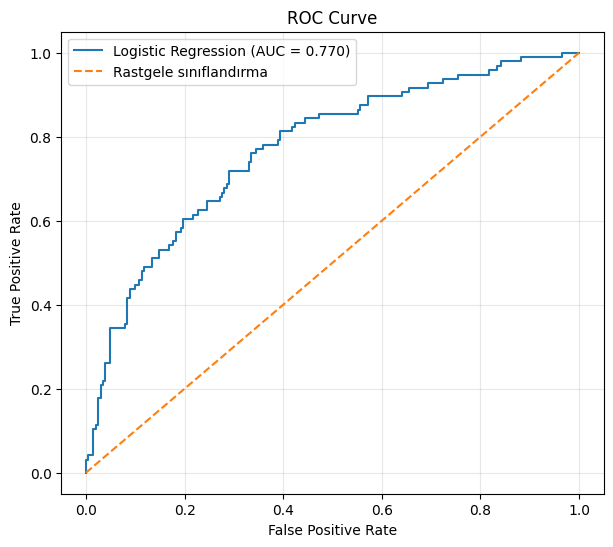

In [40]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y, oof_predictions)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y, oof_predictions):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Rastgele sınıflandırma")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## **Precision-Recall Eğrisi**

Precision-Recall eğrisi, farklı karar eşiklerinde kesinlik (precision) ve duyarlılık (recall) arasındaki ilişkiyi göstermektedir.

Pozitif sınıfın azınlıkta bulunması nedeniyle bu eğri modelin değerlendirilmesinde önemlidir.

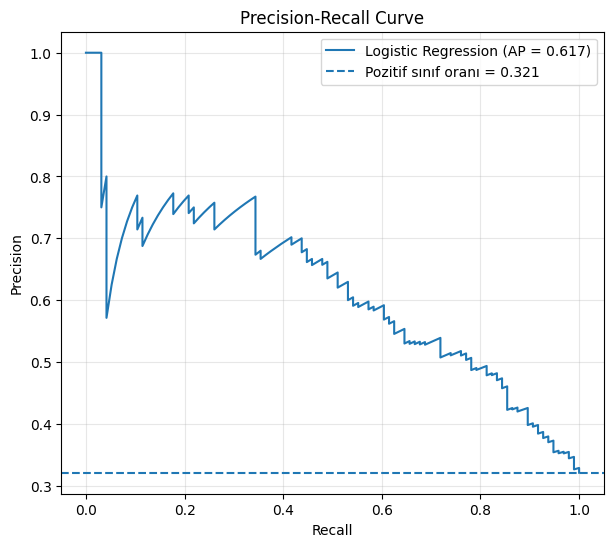

In [41]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y, oof_predictions
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (AP = {average_precision_score(y, oof_predictions):.3f})"
)

plt.axhline(
    y.mean(),
    linestyle="--",
    label=f"Pozitif sınıf oranı = {y.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## **Kalibrasyon Eğrisi**

Kalibrasyon eğrisi, modelin tahmin ettiği ölüm olasılıkları ile gözlenen ölüm oranları arasındaki uyumu incelemektedir.

İdeal kalibrasyonda tahmin edilen olasılıklar ile gerçekleşen olay oranları birbirine yakın olmalıdır.

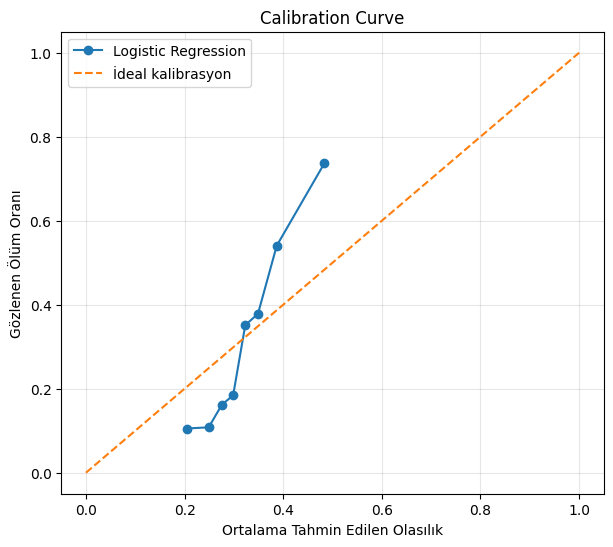

In [42]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y,
    oof_predictions,
    n_bins=8,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="İdeal kalibrasyon"
)

plt.xlabel("Ortalama Tahmin Edilen Olasılık")
plt.ylabel("Gözlenen Ölüm Oranı")
plt.title("Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## **Karışıklık Matrisi**

Karışıklık matrisi, modelin ölüm gerçekleşen ve gerçekleşmeyen hastaları ne ölçüde doğru sınıflandırdığını incelemek amacıyla kullanılacaktır.

Bu analizde doğru tahminlerin yanı sıra yanlış pozitif ve yanlış negatif tahminler de değerlendirilecektir.

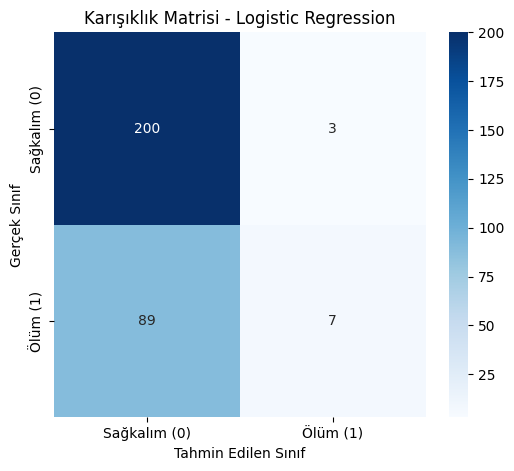

Karışıklık Matrisi:
[[200   3]
 [ 89   7]]


In [43]:
from sklearn.metrics import confusion_matrix

# Varsayılan eşik değeri: 0.50
threshold = 0.50

# Olasılıkları sınıf tahminlerine dönüştürme
y_pred = (oof_predictions >= threshold).astype(int)

# Karışıklık matrisi
cm = confusion_matrix(y, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sağkalım (0)", "Ölüm (1)"],
    yticklabels=["Sağkalım (0)", "Ölüm (1)"]
)

plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.title("Karışıklık Matrisi - Logistic Regression")
plt.show()

print("Karışıklık Matrisi:")
print(cm)

## **Sınıflandırma Performans Ölçütleri**

Modelin sınıflandırma performansı Accuracy, Precision, Recall, Specificity ve F1-score ölçütleriyle değerlendirilecektir.

Özellikle Recall (duyarlılık), ölüm gerçekleşen hastaların ne kadarının doğru tespit edildiğini göstermesi nedeniyle önemlidir.

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Karışıklık matrisinden değerleri alma
tn, fp, fn, tp = cm.ravel()

# Performans ölçütleri
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred, zero_division=0)
recall = recall_score(y, y_pred, zero_division=0)
specificity = tn / (tn + fp)
f1 = f1_score(y, y_pred, zero_division=0)

# Sonuç tablosu
classification_results = pd.DataFrame({
    "Olcut": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "Specificity",
        "F1-score"
    ],
    "Deger": [
        accuracy,
        precision,
        recall,
        specificity,
        f1
    ]
})

display(classification_results.round(4))

,Olcut,Deger
0,Accuracy,0.6923
1,Precision,0.7000
2,Recall (Sensitivity),0.0729
3,Specificity,0.9852
4,F1-score,0.1321


### Karışıklık Matrisi ve Sınıflandırma Sonuçlarının Değerlendirilmesi

0.50 karar eşiği kullanılarak elde edilen karışıklık matrisi incelendiğinde modelin sağkalım sınıfını tahmin etmede başarılı olduğu ancak ölüm sınıfını belirlemede yetersiz kaldığı görülmektedir.

Model, gerçek ölüm vakası bulunan 96 hastanın yalnızca 7'sini doğru sınıflandırırken 89 hastayı yanlışlıkla sağkalım sınıfına atamıştır. Buna karşılık, sağkalım grubundaki 203 hastanın 200'ü doğru tahmin edilmiştir.

Accuracy değeri 0.6923 olmasına rağmen Recall değerinin 0.0729 olması modelin ölüm vakalarının büyük çoğunluğunu tespit edemediğini göstermektedir. Bu nedenle Accuracy tek başına yeterli bir performans ölçütü değildir.

Sonuçlar, Logistic Regression modelinin mevcut 0.50 karar eşiğinde sağkalım sınıfına daha fazla yöneldiğini göstermektedir. İlerleyen analizlerde karar eşiğinin etkisi ayrıca incelenecektir.

## **Karar Eşiğinin Performansa Etkisi**

Lojistik Regresyon modeli, her hasta için 0 ile 1 arasında bir ölüm olasılığı üretmektedir. Bu olasılığın hangi sınıfa dönüştürüleceğini belirleyen değer karar eşiğidir.

Varsayılan olarak 0.50 eşik değeri kullanılmaktadır. Ancak farklı eşik değerleri kullanıldığında Precision, Recall ve F1-score gibi performans ölçütleri değişebilir.

Bu nedenle farklı karar eşikleri karşılaştırılarak modelin ölüm vakalarını tespit etme başarısı incelenecektir.

In [45]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (oof_predictions >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y, y_pred_threshold).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y, y_pred_threshold, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,Specificity,F1-score
0,0.2,0.3345,0.9896,0.0690,0.5000
1,0.3,0.4788,0.8229,0.5764,0.6054
2,0.4,0.7174,0.3438,0.9360,0.4648
3,0.5,0.7000,0.0729,0.9852,0.1321
4,0.6,0.7500,0.0312,0.9951,0.0600


0.50 eşiğinde ölüm vakalarının çoğunu kaçırırken, 0.30 eşiğinde ölüm vakalarının çok daha büyük bölümünü yakalayabiliyoruz.

Eşik düştükçe: Model daha fazla hastayı ölüm sınıfına atıyor. Böylece Recall yükseliyor, ancak yanlış pozitifler de artıyor ve Specificity düşüyor.

Eşik yükseldikçe: Model ölüm demekte daha seçici oluyor. Precision ve Specificity genellikle yükselirken Recall düşüyor.

### Karar Eşiği Analizi Sonuçlarının Değerlendirilmesi

Farklı karar eşikleri incelendiğinde, eşik değerinin düşürülmesinin Recall değerini artırdığı ancak Specificity değerini azalttığı görülmüştür.

0.20 eşik değerinde Recall 0.9896'ya yükselirken Specificity 0.0690'a düşmüştür. Bu durum modelin ölüm vakalarının neredeyse tamamını yakalamasına rağmen çok sayıda sağkalım vakasını yanlış sınıflandırdığını göstermektedir.

0.30 eşik değerinde Recall 0.8229, Precision 0.4788 ve F1-score 0.6054 olarak elde edilmiştir. İncelenen eşik değerleri arasında en yüksek F1-score bu eşikte gözlenmiştir.

Bulgular, karar eşiğinin modelin sınıflandırma davranışını önemli ölçüde etkilediğini göstermektedir. 0.30 değeri yalnızca incelenen eşikler arasındaki karşılaştırmayla en iyi sonuca götürebiilr ama bağımsız bir doğrulama yapılmadan nihai veya klinik açıdan en uygun eşik olarak kabul edilmemelidir.

## **Kalibrasyon Analizi**

Lojistik Regresyon modeli yalnızca sınıf tahmini değil aynı zamanda her hasta için ölüm olayına ilişkin olasılık tahmini üretmektedir.

Kalibrasyon analizi, modelin tahmin ettiği olasılıkların gözlenen ölüm oranlarıyla ne ölçüde uyumlu olduğunu değerlendirmek amacıyla kullanılmaktadır.

İyi kalibre edilmiş bir modelde örneğin %70 ölüm olasılığı verilen hasta grubunda gözlenen ölüm oranının da yaklaşık %70 olması beklenir.

Bu analizde Nested Cross-Validation sonucunda elde edilen dış katman tahminleri kullanılacaktır.

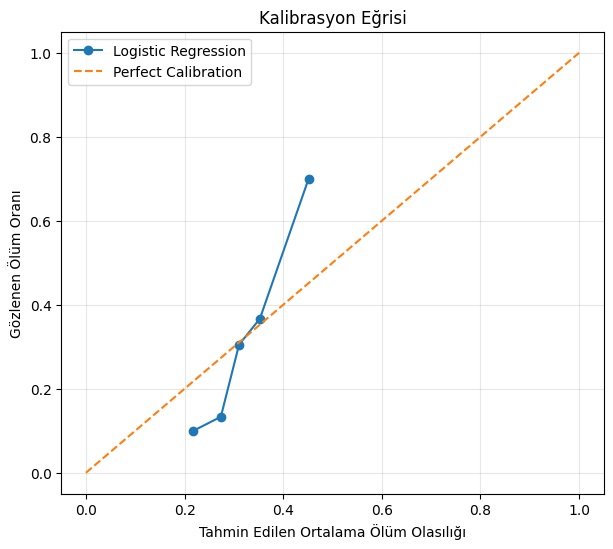

In [46]:
from sklearn.calibration import calibration_curve

fraction_of_positives, mean_predicted_value = calibration_curve(
    y,
    oof_predictions,
    n_bins=5,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Logistic Regression"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")

plt.xlabel("Tahmin Edilen Ortalama Ölüm Olasılığı")
plt.ylabel("Gözlenen Ölüm Oranı")
plt.title("Kalibrasyon Eğrisi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Kalibrasyon Eğrisi Sonuçlarının Değerlendirilmesi

Kalibrasyon eğrisi incelendiğinde modelin olasılık tahminlerinin ideal kalibrasyon çizgisiyle tüm aralıklarda uyumlu olmadığı görülmektedir.

İlk iki grupta gözlenen ölüm oranı tahmin edilen ortalama olasılıktan düşük olduğundan model ölüm olasılığını olduğundan yüksek tahmin etmiştir. Üçüncü ve dördüncü gruplarda tahminler ideal kalibrasyon çizgisine daha yakındır.

Son grupta ise tahmin edilen ortalama ölüm olasılığı yaklaşık 0.45 iken gözlenen ölüm oranı yaklaşık 0.70'tir. Bu durum modelin bu gruptaki ölüm olasılığını olduğundan düşük tahmin ettiğini göstermektedir.

Genel olarak modelin olasılık tahminlerinde kalibrasyon farklılıkları bulunmaktadır. Bu nedenle modelin ayırt etme başarısının yanı sıra olasılık tahminlerinin güvenilirliği de dikkate alınmalıdır.

## **Brier Skoru**
Brier skoru, olasılık tahminlerinin gerçek sonuçlara ne kadar yakın olduğunu ölçer. Düşük olması daha iyidir.

In [49]:
brier_oof = brier_score_loss(y, oof_predictions)

print("Pooled OOF Brier Score:", round(brier_oof, 4))

Pooled OOF Brier Score: 0.191


### Brier Skoru Sonuçlarının Değerlendirilmesi

Nested Cross-Validation kapsamında elde edilen dış katman olasılık tahminleri kullanılarak hesaplanan Pooled OOF Brier skoru 0.1910 olarak bulunmuştur.

Brier skorunun düşük olması, modelin olasılık tahminlerinin gerçek sonuçlara daha yakın olduğunu gösterir. Ancak bu değer tek başına kalibrasyon başarısını değerlendirmek için yeterli değildir. Bu nedenle Brier skoru, kalibrasyon eğrisiyle birlikte yorumlanmıştır.

Kalibrasyon eğrisi, modelin bazı olasılık gruplarında tahmin edilen ve gözlenen ölüm oranları arasında farklılıklar bulunduğunu göstermiştir.